# Subplots and multi-panel figures

## Learning objectives

By the end of this notebook you will be able to:

- create grids of plots with plt.subplots
- share axes between panels
- loop over panels to plot groups
- build uneven layouts with GridSpec and subplot_mosaic
- label panels and add a figure title

## Introduction

Several related plots side by side let the reader compare them directly: one panel per group, or
different views of the same data. Multi-panel figures are standard in reports and papers.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
RAW = "../datasets/raw/"

In [2]:
labs = pd.read_csv(RAW + "lab_results.csv")
patients = pd.read_csv(RAW + "patients.csv")

## A grid of plots

`plt.subplots(nrows, ncols)` returns the figure and an array of Axes.

(2, 2)


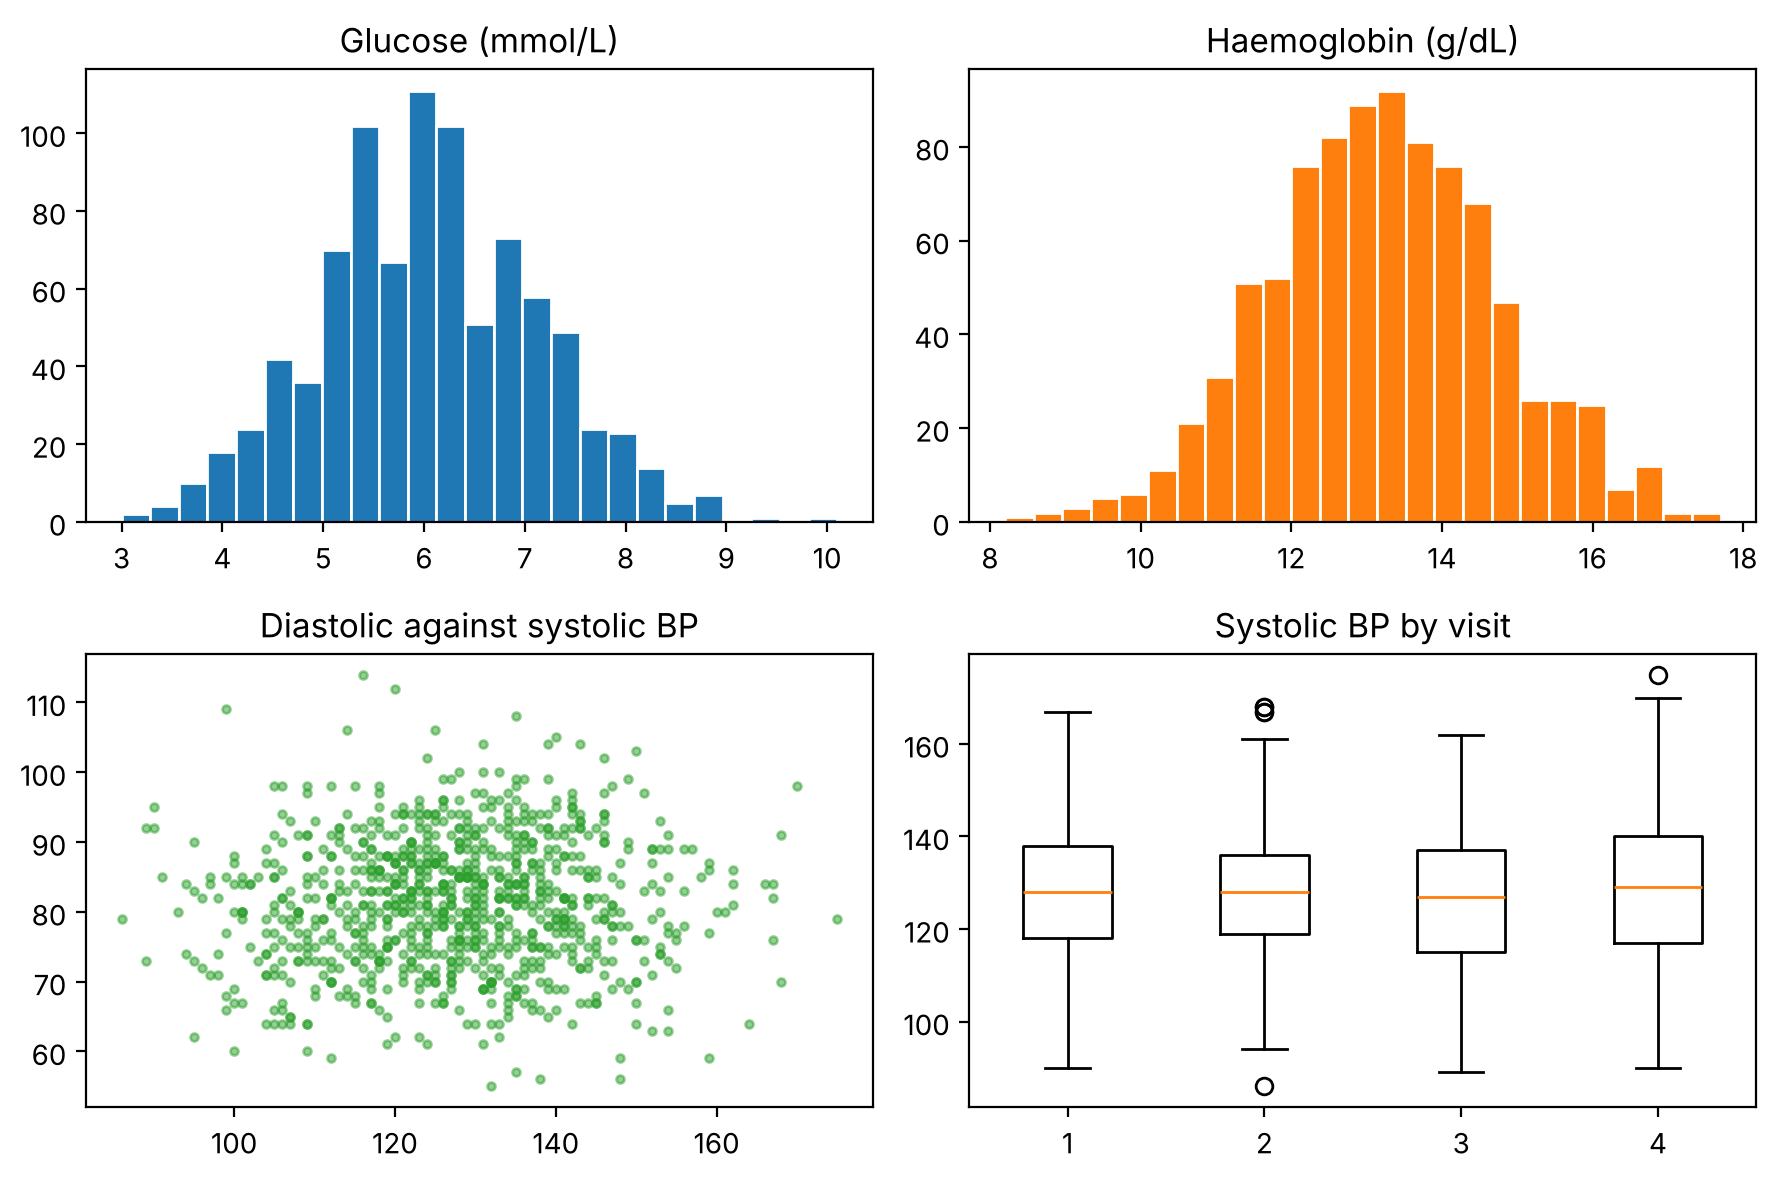

In [3]:
fig, axes = plt.subplots(2, 2, figsize=(9, 6))
print(axes.shape)

axes[0, 0].hist(labs["glucose_mmol"], bins=25, edgecolor="white")
axes[0, 0].set_title("Glucose (mmol/L)")
axes[0, 1].hist(labs["haemoglobin_g_dl"], bins=25, edgecolor="white", color="C1")
axes[0, 1].set_title("Haemoglobin (g/dL)")
axes[1, 0].scatter(labs["systolic_bp"], labs["diastolic_bp"], s=8, alpha=0.5, color="C2")
axes[1, 0].set_title("Diastolic against systolic BP")
axes[1, 1].boxplot([labs.loc[labs["visit"] == v, "systolic_bp"] for v in sorted(labs["visit"].unique())])
axes[1, 1].set_title("Systolic BP by visit")
fig.tight_layout()
plt.show()

`tight_layout()` (or `layout="constrained"` in `plt.subplots`) adjusts spacing so titles and labels do
not overlap.

## Looping over panels

`axes.flat` goes through all panels in order, which pairs well with groups:

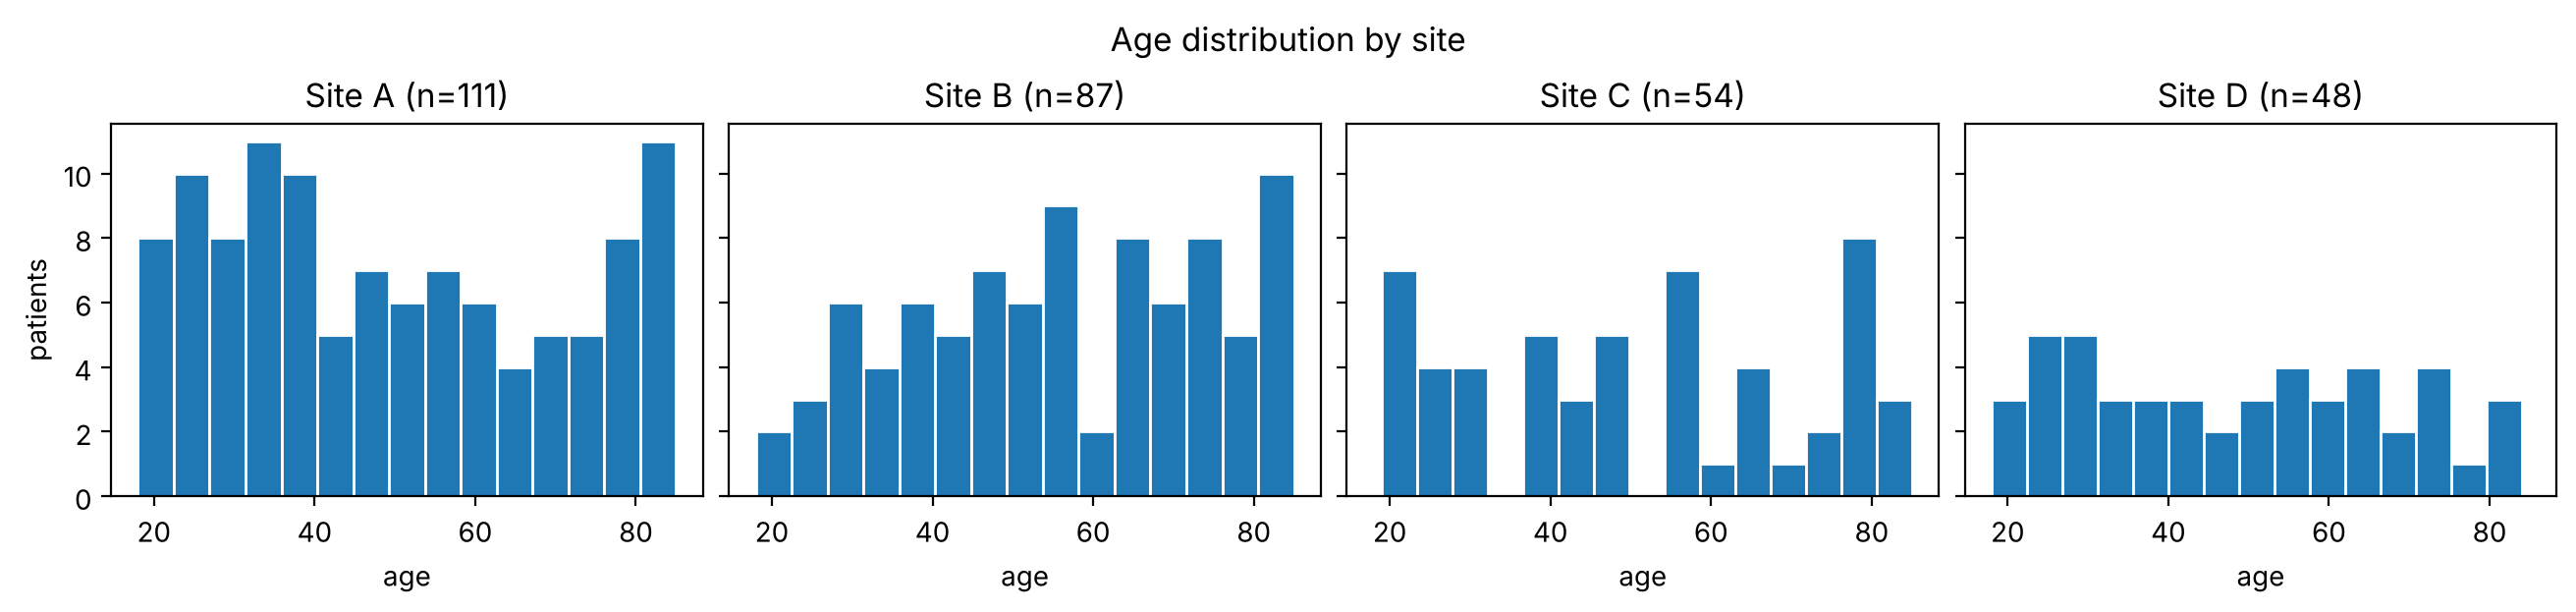

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3), sharex=True, sharey=True, layout="constrained")
for ax, (site, g) in zip(axes.flat, patients.groupby("site")):
    ax.hist(g["age"], bins=15, edgecolor="white")
    ax.set_title(f"{site} (n={len(g)})")
    ax.set_xlabel("age")
axes[0].set_ylabel("patients")
fig.suptitle("Age distribution by site")
plt.show()

`sharex=True, sharey=True` give every panel the same scales, so bar heights can be compared across panels.
Without shared axes each panel scales itself, and a small group can look as large as a big one.

## Small multiples instead of a crowded chart

Ten lines on one plot are hard to follow. One small panel per line, on shared axes, is usually clearer.

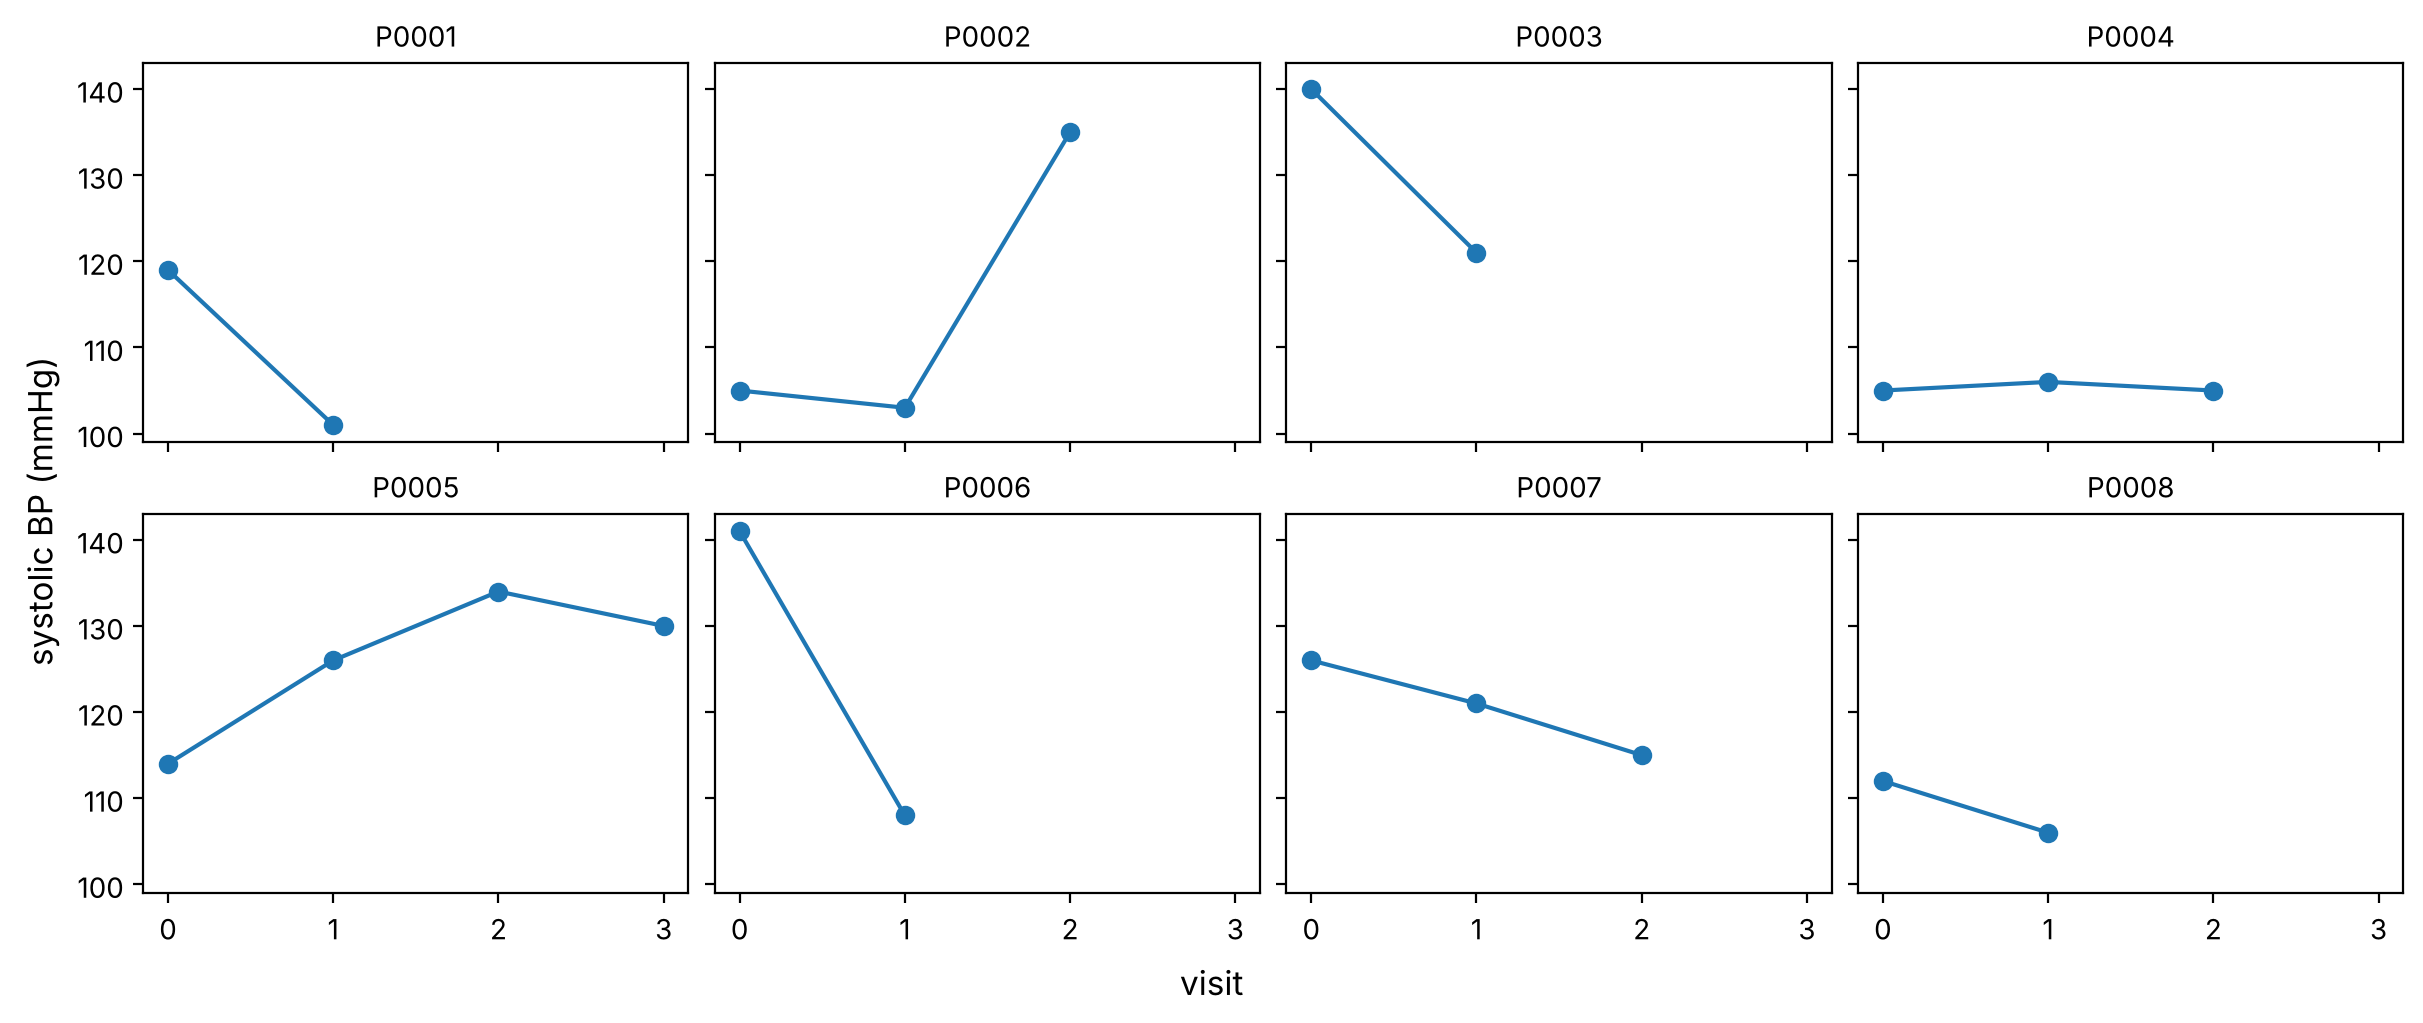

In [5]:
sample_ids = labs["patient_id"].drop_duplicates().iloc[:8]
fig, axes = plt.subplots(2, 4, figsize=(12, 5), sharex=True, sharey=True, layout="constrained")
for ax, pid in zip(axes.flat, sample_ids):
    d = labs[labs["patient_id"] == pid]
    ax.plot(d["visit"], d["systolic_bp"], marker="o")
    ax.set_title(pid, fontsize=10)
fig.supxlabel("visit")
fig.supylabel("systolic BP (mmHg)")
plt.show()

## Uneven layouts

`subplot_mosaic` draws a layout from a text picture. Each letter is a panel; repeating a letter makes it span.

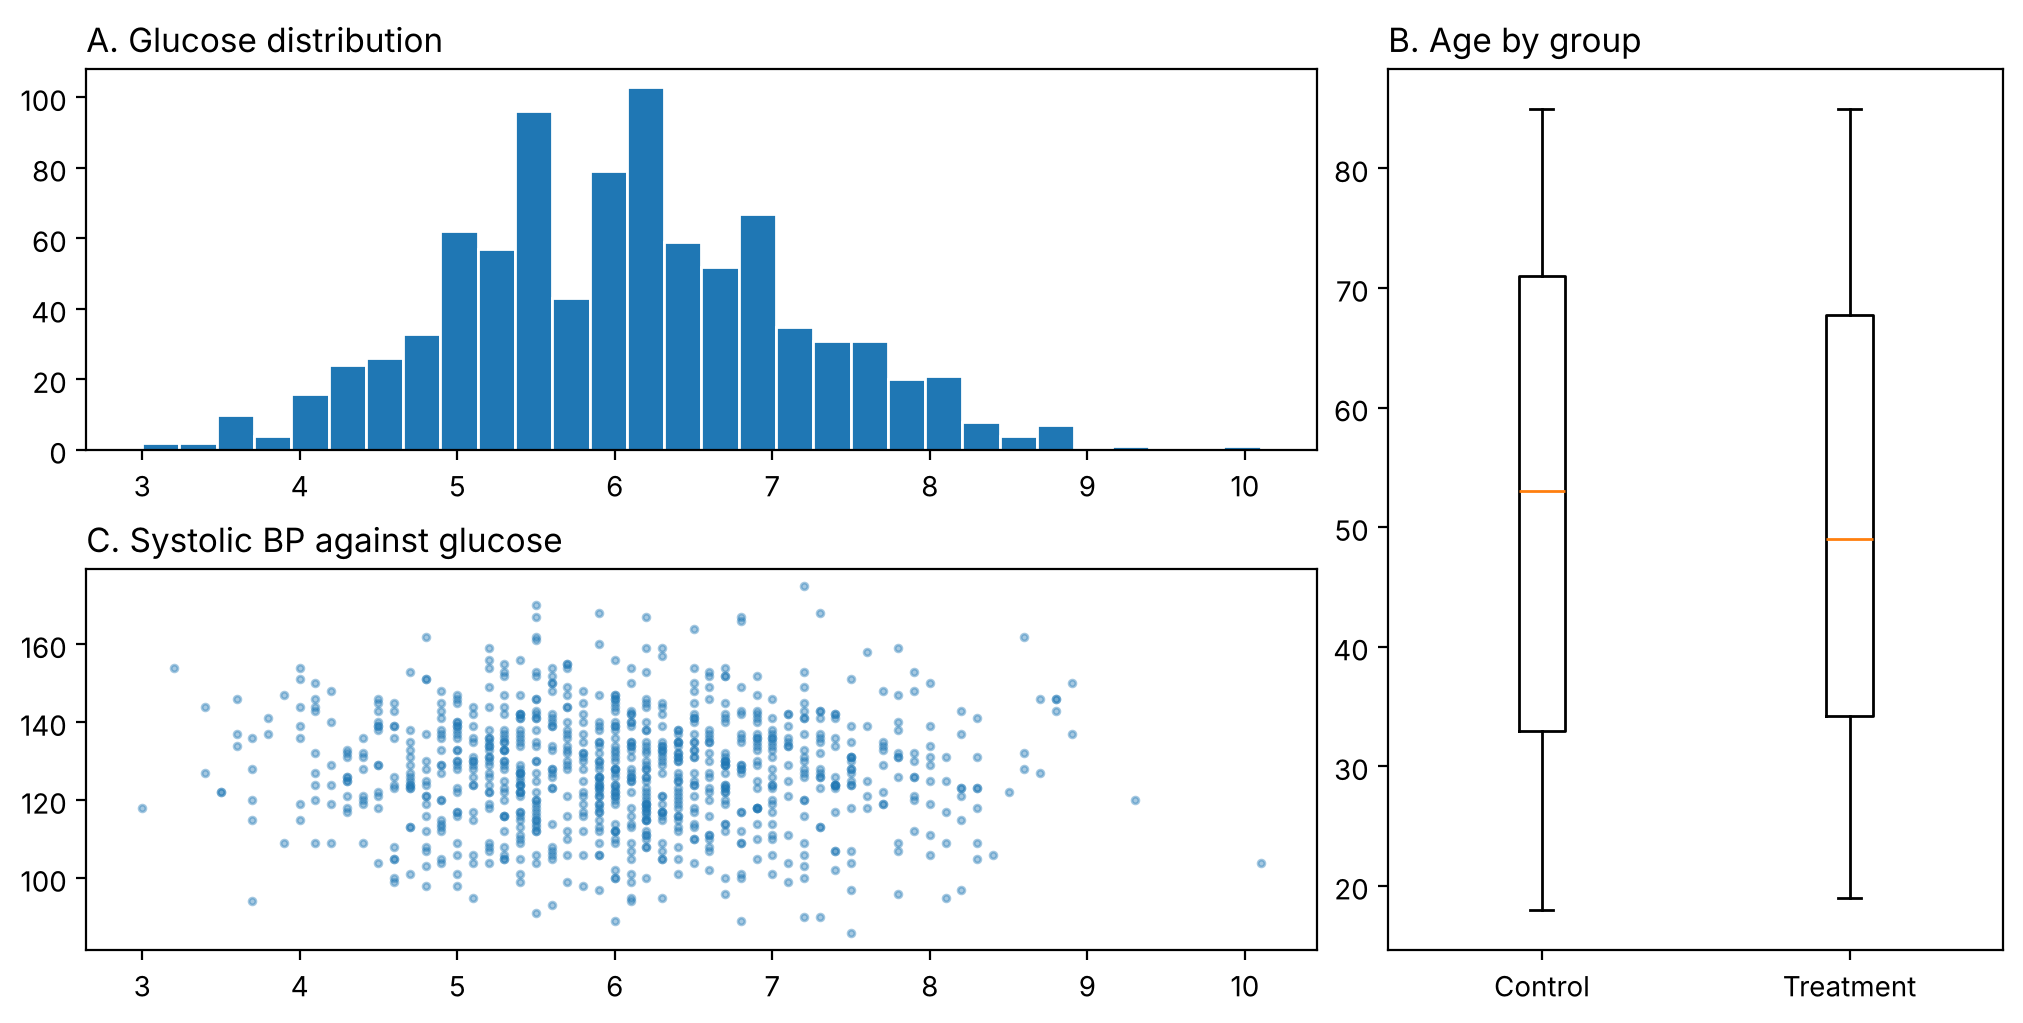

In [6]:
fig, ax = plt.subplot_mosaic("AAB;CCB", figsize=(10, 5), layout="constrained")
ax["A"].hist(labs["glucose_mmol"], bins=30, edgecolor="white")
ax["A"].set_title("A. Glucose distribution", loc="left")
ax["B"].boxplot([patients.loc[patients["group"] == g, "age"] for g in ["Control", "Treatment"]],
                tick_labels=["Control", "Treatment"])
ax["B"].set_title("B. Age by group", loc="left")
ax["C"].scatter(labs["glucose_mmol"], labs["systolic_bp"], s=6, alpha=0.4)
ax["C"].set_title("C. Systolic BP against glucose", loc="left")
plt.show()

Panel letters (A, B, C) with `loc="left"` are the usual way to refer to panels in a report's text.

`GridSpec` gives the same control with row and column positions:

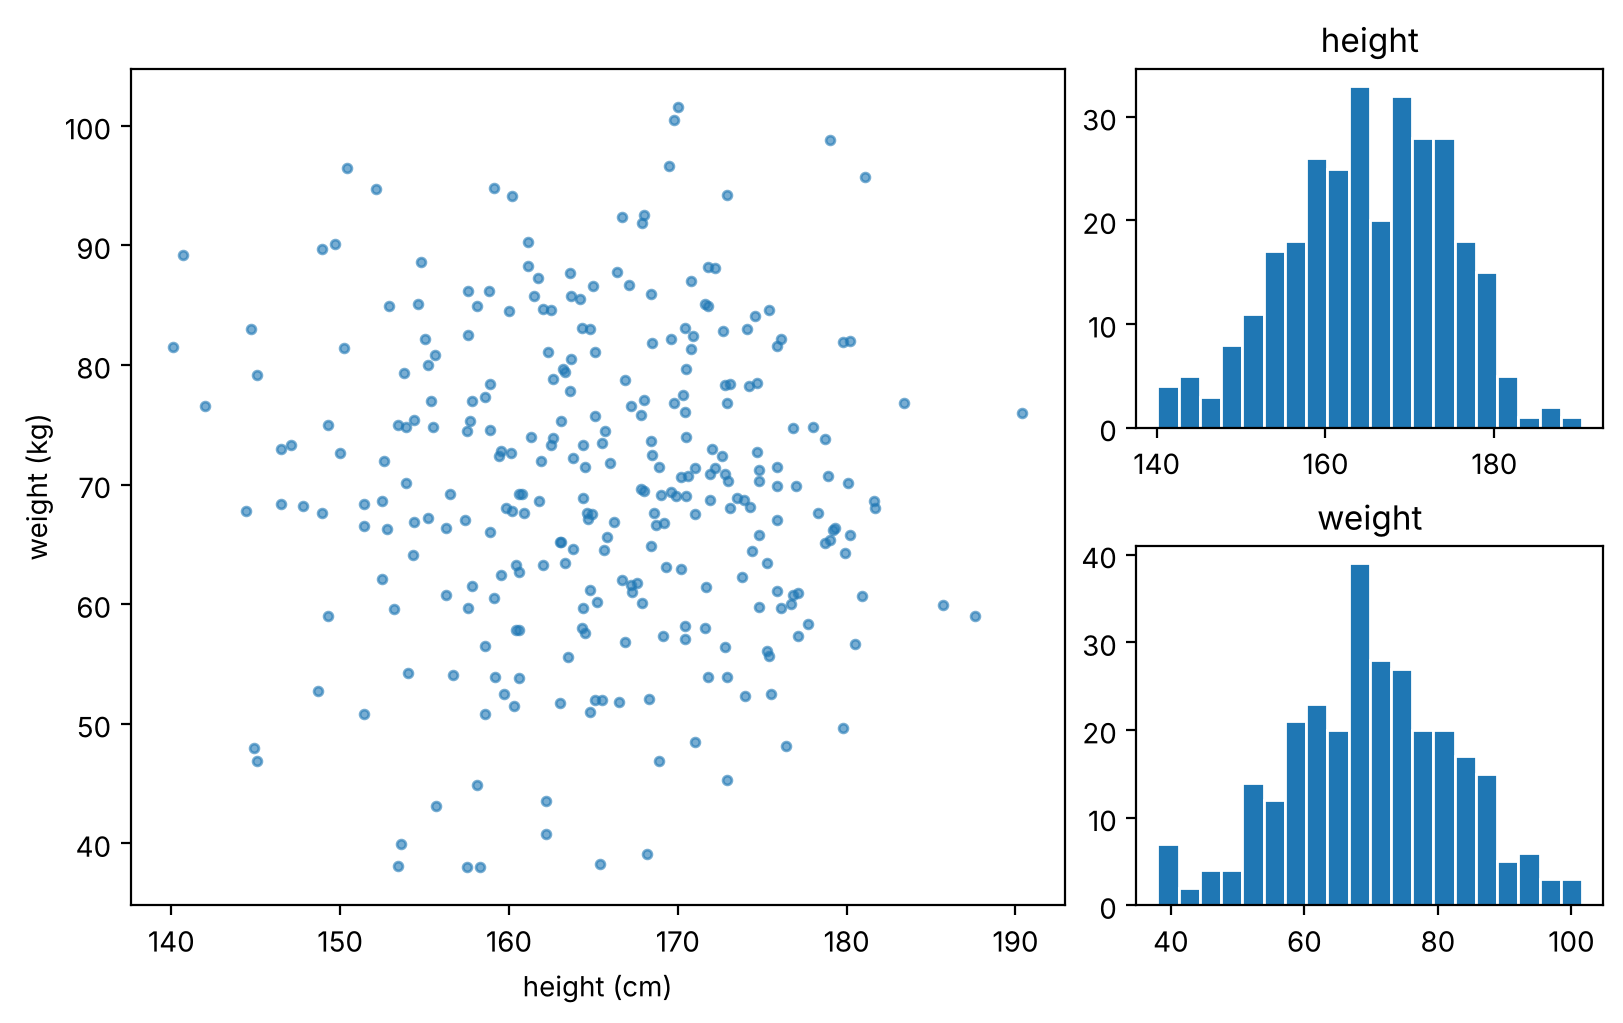

In [7]:
from matplotlib.gridspec import GridSpec
fig = plt.figure(figsize=(8, 5), layout="constrained")
gs = GridSpec(2, 3, figure=fig)
main = fig.add_subplot(gs[:, :2])
top = fig.add_subplot(gs[0, 2])
bottom = fig.add_subplot(gs[1, 2])
main.scatter(patients["height_cm"], patients["weight_kg"], s=10, alpha=0.6)
main.set_xlabel("height (cm)"); main.set_ylabel("weight (kg)")
top.hist(patients["height_cm"], bins=20, edgecolor="white"); top.set_title("height")
bottom.hist(patients["weight_kg"].dropna(), bins=20, edgecolor="white"); bottom.set_title("weight")
plt.show()

## Two measures with different units

When two variables have different units, put them in **two panels with a shared x-axis**, not on one
plot with two y-axes:

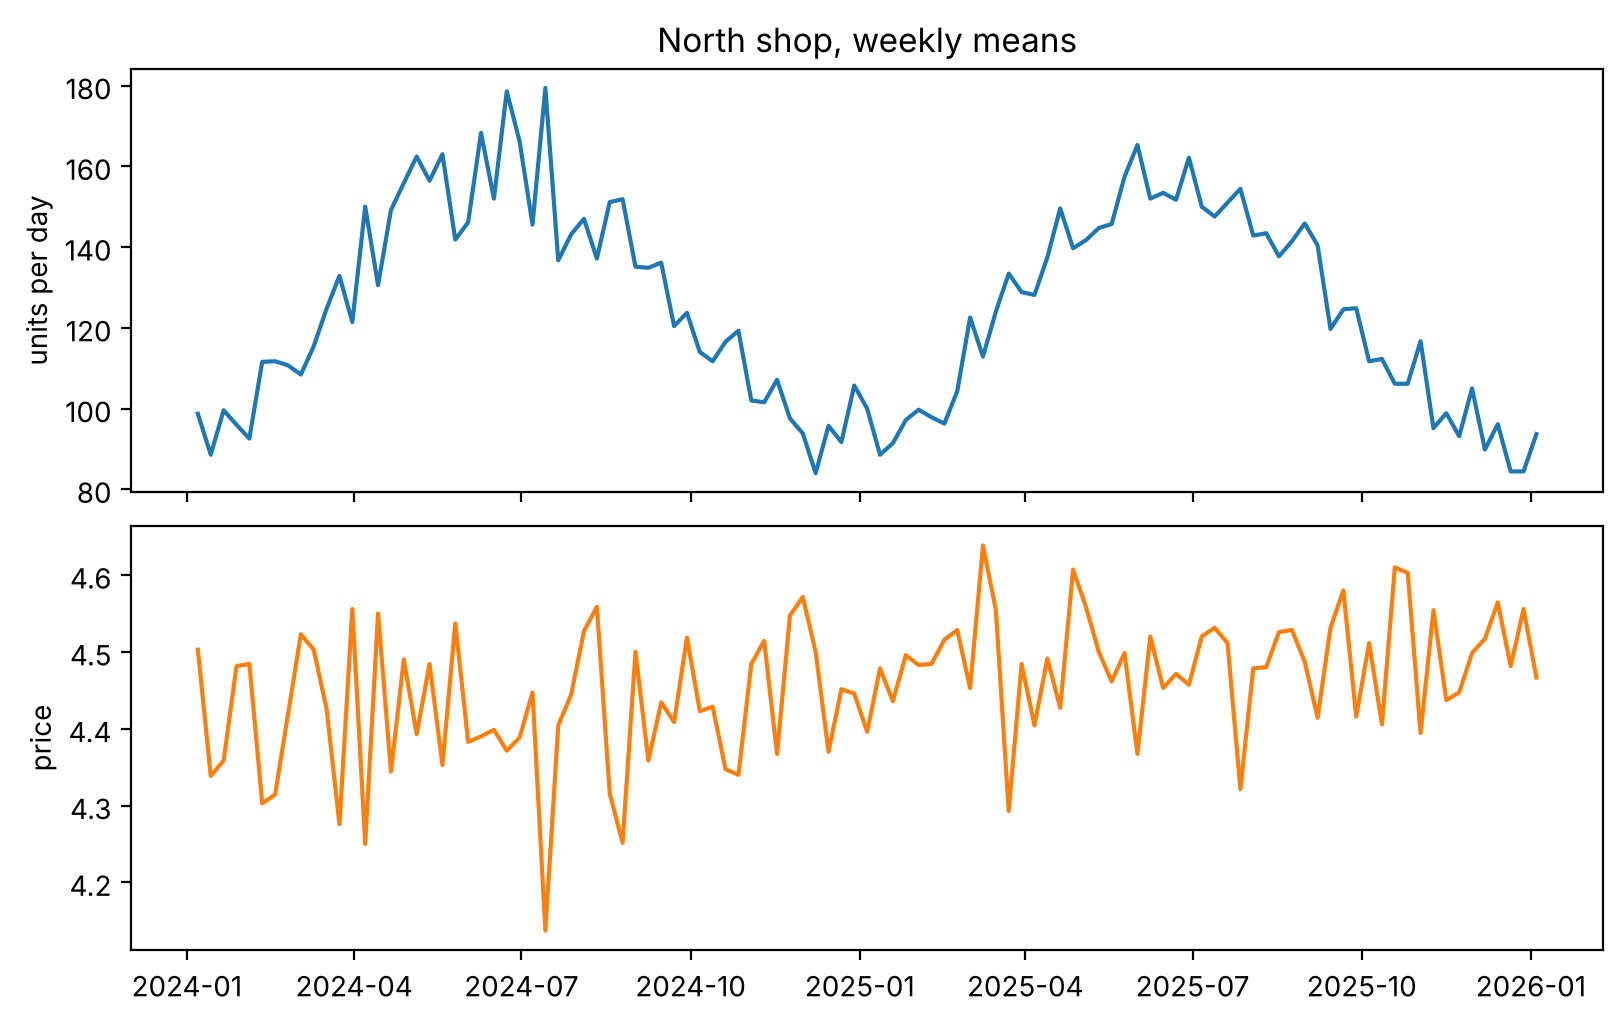

In [8]:
sales = pd.read_csv(RAW + "daily_sales.csv", parse_dates=["date"])
north = sales[sales["shop"] == "North"].set_index("date").resample("W")[["units", "price"]].mean()

fig, (top, bottom) = plt.subplots(2, 1, figsize=(8, 5), sharex=True, layout="constrained")
top.plot(north.index, north["units"])
top.set_ylabel("units per day")
bottom.plot(north.index, north["price"], color="C1")
bottom.set_ylabel("price")
top.set_title("North shop, weekly means")
plt.show()

## Practise

Exercises for this folder are in `exercises/Matplotlib_Exercises.ipynb`.

## Further reading

- [Matplotlib user guide](https://matplotlib.org/stable/users/index.html)
- [Arranging multiple Axes](https://matplotlib.org/stable/users/explain/axes/arranging_axes.html)
- [subplot_mosaic](https://matplotlib.org/stable/users/explain/axes/mosaic.html)
- [Constrained layout](https://matplotlib.org/stable/users/explain/axes/constrainedlayout_guide.html)